# IMSTE visualization gallery

Try the reusable renderers in `imste.visualization` on the standard MNIST, Fashion-MNIST, and Kuzushiji-MNIST image datasets. Choose a dataset and sample size below, fit IMSTE once, then use the same fitted model for the colored embedding, kNN union, ellipses, and interactive force view.

The datasets are downloaded on first use and cached locally. Install optional dependencies with `python -m pip install -e ".[notebook]"`.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import StandardScaler

repo_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / 'imste' / '__init__.py').is_file()),
    None,
)
if repo_root is None:
    raise RuntimeError('Open this notebook from the IteratedMinimumSpanningTree checkout.')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from notebooks.high_dim_mst_gallery import _load_kmnist, _load_openml, _stratified_sample
from imste.visualization import (
    interactive_force,
    plot_ellipses,
    plot_embedding,
    plot_knn_union,
)

plt.rcParams['figure.dpi'] = 110


## Choose and load a standard image dataset

Set `DATASET` to `'mnist'`, `'fashion_mnist'`, or `'kmnist'`. `N_SAMPLES` controls the stratified subset used for the fit; keeping it around 1,000 makes this interactive gallery practical on a laptop. Features are standardized after sampling, matching the other high-dimensional IMSTE notebooks.


In [2]:
DATASET = 'mnist'  # 'mnist', 'fashion_mnist', or 'kmnist'
N_SAMPLES = 5_000
RANDOM_STATE = 18

DATASET_LOADERS = {
    'mnist': lambda: _load_openml('mnist_784'),
    'fashion_mnist': lambda: _load_openml('Fashion-MNIST'),
    'kmnist': _load_kmnist,
}
DATASET_NAMES = {
    'mnist': 'MNIST',
    'fashion_mnist': 'Fashion-MNIST',
    'kmnist': 'Kuzushiji-MNIST',
}
if DATASET not in DATASET_LOADERS:
    raise ValueError(f'DATASET must be one of {tuple(DATASET_LOADERS)}.')

X_all, labels_all = DATASET_LOADERS[DATASET]()
X_features, class_codes = _stratified_sample(
    X_all,
    labels_all,
    max_samples=N_SAMPLES,
    random_state=RANDOM_STATE,
)
X_features = StandardScaler().fit_transform(X_features.astype(np.float32))
obs = pd.DataFrame({'class': class_codes.astype(str)})

print(
    f'{DATASET_NAMES[DATASET]} · {len(X_features):,} images × '
    f'{X_features.shape[1]:,} pixels · {obs["class"].nunique()} classes'
)
obs.head()


MNIST · 5,000 images × 784 pixels · 10 classes


,class
0,0
1,0
2,3
3,9
4,6


## Fit a compact IMSTE example

Adjust `FIT_PARAMS` to explore the embedding settings. The main knobs are the number of spanning trees (`n_msts`), optimization epochs (`n_epochs`), and negative samples per positive edge (`negative_ratio`). FAMST is the default graph builder, and optimization uses the MPS device by default (`device="mps"`). The estimator retains its coordinates in `embedding_`; every renderer below accepts the fitted estimator directly.


In [3]:
from imste import IteratedMinimumSpanningTreeEmbedder

FIT_PARAMS = {
    'n_msts': 40,
    'n_epochs': 2000,
    'mst_method': 'famst',
    'device': 'mps',
    'negative_ratio': 30,
    'random_state': RANDOM_STATE,
}
mapper = IteratedMinimumSpanningTreeEmbedder(**FIT_PARAMS)
embedding = mapper.fit_transform(X_features)
print(f'Embedding shape: {embedding.shape}')
print(f'Graph build: {mapper.graph_construction_time_:.2f}s · fit: {mapper.fit_time_:.2f}s')


Embedding shape: (5000, 2)
Graph build: 1.07s · fit: 22.04s


## 1. Colored embedding

Color the fitted IMSTE coordinates by the image class labels.


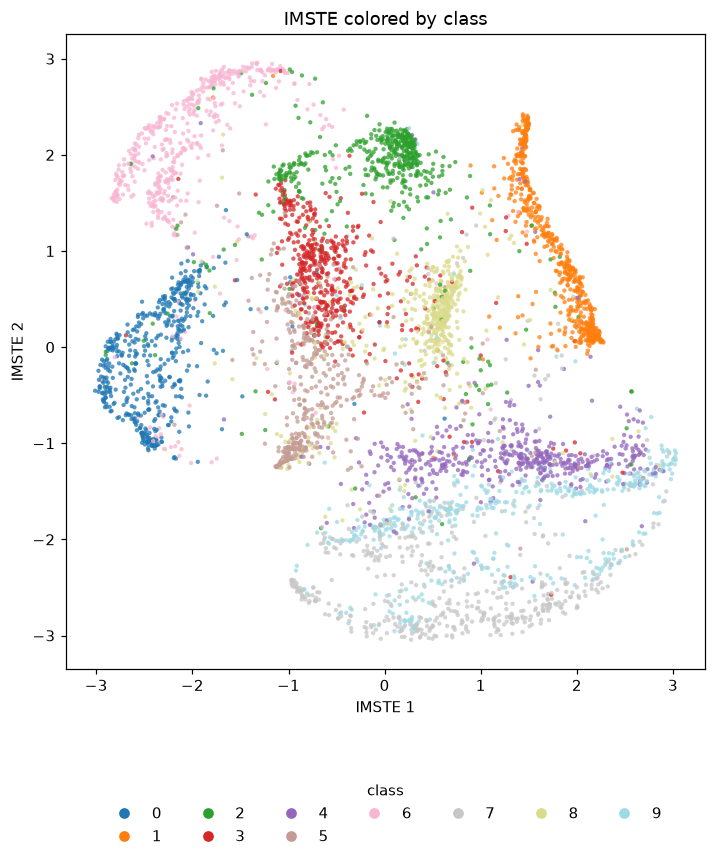

In [4]:
fig, ax = plot_embedding(
    mapper,
    obs,
    color_keys=('class',),
    point_size=8,
    point_alpha=0.75,
    legend_position='bottom',
)
plt.show()


## 2. kNN neighborhood union

For each class, the renderer cross-validates a kNN classifier, removes misclassified rows, optionally filters local-distance outliers, and draws the union of same-class neighborhood hulls. Adjust these settings and rerun the cell. Set `distance_std_threshold=None` to turn off that filter.

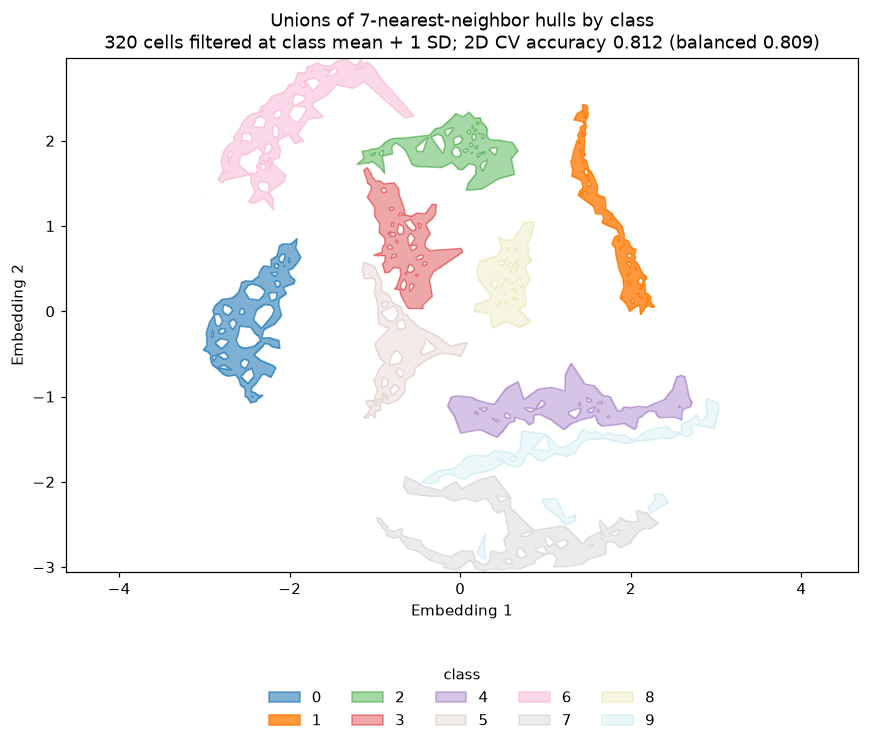

In [5]:
KNN_VIEW = {
    'k': 7,
    'cv_neighbors': 5,
    'cv_splits': 5,
    'random_state': RANDOM_STATE,
    'distance_std_threshold': 1.0,
    'alpha_range': (0.2, 0.8),
    'legend_position': 'bottom',
}
fig, ax = plot_knn_union(mapper, obs, label_key='class', **KNN_VIEW)
plt.show()


## 3. Ellipses over the embedding

Ellipses summarize connected regions from the filtered kNN union. The renderer splits complex regions into a few ellipses when that improves the area-precision and coverage estimates.

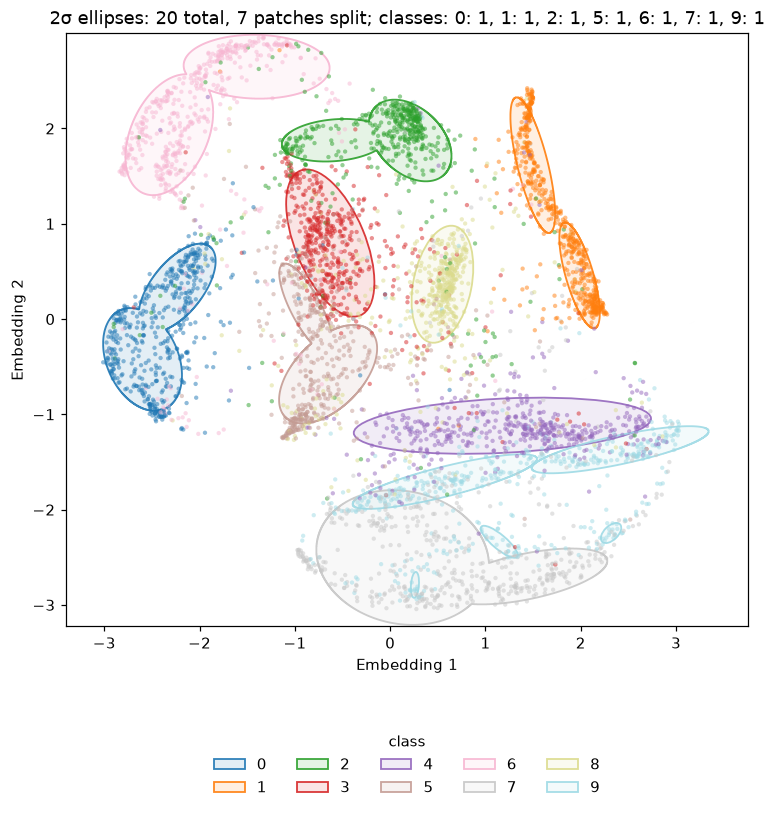

In [6]:
ELLIPSE_VIEW = {
    'k': KNN_VIEW['k'],
    'cv_neighbors': KNN_VIEW['cv_neighbors'],
    'cv_splits': KNN_VIEW['cv_splits'],
    'random_state': RANDOM_STATE,
    'distance_std_threshold': KNN_VIEW['distance_std_threshold'],
    'n_std': 2.0,
    'max_ellipses_per_region': 2,
    'min_precision': 0.7,
    'min_recall': 0.7,
    'point_size': 8,
    'point_alpha': 0.5,
    'legend_position': 'bottom',
}
fig, ax = plot_ellipses(mapper, obs, label_key='class', **ELLIPSE_VIEW)
plt.show()


## 4. Interactive force view

The controls adjust the number of same- and different-label neighbors, force balance, spring rest length, iteration count, and how much of the adjusted layout to display. Neighbor identities stay fixed from the original coordinates.

In [7]:
force_view = interactive_force(
    mapper,
    obs,
    label_key='class',
    initial_k=8,
    initial_iterations=20,
    initial_distance_fraction=0.3,
    max_k=30,
    max_iterations=150,
    point_size=8,
)
display(force_view)


## Use another dataset or your own embedding

Change `DATASET` in the loader cell to switch among MNIST, Fashion-MNIST, and Kuzushiji-MNIST, then rerun the loader, fit, and renderer cells. For your own data, replace `X_features` and `obs` with your feature matrix and aligned metadata.

```python
fig, ax = plot_knn_union(mapper, metadata, label_key='class', k=7)
# Or pass mapper.embedding_ instead of mapper.
```
